# Implementation and Time Analysis of Matrix Chain Multiplication using Dynamic Programming

**Problem:** Given a chain of matrices `A1, A2, ..., An` to multiply together,
matrix multiplication is **associative** (the result is the same regardless of
how you parenthesize the chain), but the **number of scalar multiplications**
needed can differ enormously depending on the order you multiply them in.

Given the dimensions of each matrix (matrix `Ai` has dimensions `p[i-1] x p[i]`,
so the chain is described by a list `p` of length `n+1`), find the
parenthesization (order of multiplication) that **minimizes the total number of
scalar multiplications**.

This notebook covers:
- A naive recursive (brute-force) solution, to show why DP is needed
- A **Dynamic Programming (bottom-up tabulation)** solution
- Reconstructing the *actual optimal parenthesization* (not just the cost)
- User input (enter your own matrix dimensions)
- Runtime measurement, time complexity, and space complexity
- A runtime comparison between naive recursion and DP


In [1]:
# Common imports used throughout the notebook
import time
import sys
import matplotlib.pyplot as plt

sys.setrecursionlimit(10000)

def get_user_dimensions(demo_string=None):
    """Takes a comma-separated list of matrix dimensions p[0..n].

    If there are n matrices in the chain, you provide n+1 numbers: matrix i
    (1-indexed) has dimensions p[i-1] x p[i]. Example: for matrices of size
    10x20, 20x30, 30x40, you would enter: 10,20,30,40

    - Interactive use: call get_user_dimensions() with NO arguments to be
      prompted.
    - Notebook demo cells pass a fixed string so the notebook runs end-to-end
      with baked-in outputs. Remove the argument to type your own dimensions.
    """
    raw = demo_string if demo_string is not None else input(
        "Enter matrix chain dimensions p[0..n] separated by commas "
        "(e.g., for matrices 10x20, 20x30, 30x40, enter: 10,20,30,40): "
    )
    try:
        p = [int(x.strip()) for x in raw.split(',') if x.strip() != '']
        if len(p) < 2:
            raise ValueError
    except ValueError:
        print("Invalid input detected, using default dimensions [10, 20, 30, 40, 30] instead.")
        p = [10, 20, 30, 40, 30]
    return p


## 1. Naive Recursive Solution

To multiply the chain of matrices from index `i` to `j`, we must choose a
"split point" `k` (`i <= k < j`) at which to divide the chain into two
sub-chains: `(i..k)` and `(k+1..j)`. Each sub-chain is multiplied first
(recursively), and then the two resulting matrices are multiplied together.

The cost of splitting at `k` is:
```
cost(i, k) + cost(k+1, j) + p[i-1] * p[k] * p[j]
```
(the last term is the cost of multiplying the two resulting matrices, of
dimensions `p[i-1] x p[k]` and `p[k] x p[j]`).

We try **every possible split point** and take the minimum.


In [2]:
def matrix_chain_recursive(p, i, j):
    """Minimum scalar multiplications to multiply matrices A_i..A_j (1-indexed)."""
    if i == j:
        return 0   # a single matrix requires no multiplication

    min_cost = float('inf')
    for k in range(i, j):
        cost = (matrix_chain_recursive(p, i, k)
                + matrix_chain_recursive(p, k + 1, j)
                + p[i - 1] * p[k] * p[j])
        min_cost = min(min_cost, cost)

    return min_cost


In [3]:
# --- Naive Recursive: quick demo ---
demo_p = [10, 20, 30, 40, 30]   # 4 matrices: 10x20, 20x30, 30x40, 40x30
n = len(demo_p) - 1

result = matrix_chain_recursive(demo_p, 1, n)
print(f"Dimensions p = {demo_p}  (chain of {n} matrices)")
print(f"Naive Recursive -> Minimum scalar multiplications: {result}")


Dimensions p = [10, 20, 30, 40, 30]  (chain of 4 matrices)
Naive Recursive -> Minimum scalar multiplications: 30000


**Time Complexity:** `O(2^n)` roughly — more precisely `O(4^n / n^1.5)`
(related to the Catalan numbers, since the number of ways to parenthesize `n`
matrices is the `(n-1)`th Catalan number). Exponential either way, because the
same sub-chains `(i, j)` are recomputed repeatedly across different split
choices.

**Space Complexity:** `O(n)` — the recursion call stack depth.


## 2. Dynamic Programming (Bottom-Up Tabulation)

Build a table `dp[i][j]` = minimum scalar multiplications needed to multiply
matrices `Ai` through `Aj`. We fill the table by **chain length**: first all
chains of length 1 (cost 0), then length 2, then length 3, and so on up to the
full chain of length `n` — because computing `dp[i][j]` for a chain of length
`L` requires `dp[i][k]` and `dp[k+1][j]`, which are always chains **shorter**
than `L`, so they must already be filled in.

We also keep a `split` table recording the best `k` for each `(i, j)`, so we
can reconstruct the actual optimal parenthesization afterward.


In [4]:
def matrix_chain_dp(p):
    n = len(p) - 1   # number of matrices
    # dp[i][j] = min cost to multiply matrices i..j (1-indexed, i,j in [1, n])
    dp = [[0] * (n + 1) for _ in range(n + 1)]
    split = [[0] * (n + 1) for _ in range(n + 1)]   # best k for each (i, j)

    for length in range(2, n + 1):          # chain length, from 2 up to n
        for i in range(1, n - length + 2):
            j = i + length - 1
            dp[i][j] = float('inf')
            for k in range(i, j):
                cost = dp[i][k] + dp[k + 1][j] + p[i - 1] * p[k] * p[j]
                if cost < dp[i][j]:
                    dp[i][j] = cost
                    split[i][j] = k

    return dp[1][n], dp, split


In [5]:
def build_parenthesization(split, i, j):
    """Reconstructs the optimal parenthesization string, e.g. ((A1(A2A3))A4)."""
    if i == j:
        return f"A{i}"
    k = split[i][j]
    left = build_parenthesization(split, i, k)
    right = build_parenthesization(split, k + 1, j)
    return f"({left}{right})"


In [6]:
# --- Dynamic Programming: User Input + Runtime ---
# Replace the argument below with nothing, i.e. get_user_dimensions(), to type
# your own matrix dimensions interactively.
p = get_user_dimensions("10,20,30,40,30")
n = len(p) - 1

print(f"Dimensions p = {p}")
print(f"Chain of {n} matrices:")
for i in range(1, n + 1):
    print(f"  A{i}: {p[i-1]} x {p[i]}")

start = time.time()
cost_recursive = matrix_chain_recursive(p, 1, n)
end = time.time()
print(f"\nNaive Recursive -> Min cost: {cost_recursive}  |  Runtime: {(end - start) * 1000:.4f} ms")

start = time.time()
cost_dp, dp_table, split_table = matrix_chain_dp(p)
end = time.time()
print(f"Dynamic Programming -> Min cost: {cost_dp}  |  Runtime: {(end - start) * 1000:.4f} ms")

optimal_order = build_parenthesization(split_table, 1, n)
print(f"\nOptimal parenthesization: {optimal_order}")


Dimensions p = [10, 20, 30, 40, 30]
Chain of 4 matrices:
  A1: 10 x 20
  A2: 20 x 30
  A3: 30 x 40
  A4: 40 x 30

Naive Recursive -> Min cost: 30000  |  Runtime: 0.0451 ms
Dynamic Programming -> Min cost: 30000  |  Runtime: 0.0474 ms

Optimal parenthesization: (((A1A2)A3)A4)


**Time Complexity:** `O(n^3)` — there are `O(n^2)` entries `(i, j)` in the
table, and filling each entry requires trying up to `O(n)` split points `k`.

**Space Complexity:** `O(n^2)` — for the `dp` table (and the `split` table used
for reconstruction).

This is a huge improvement over the naive exponential recursion, achieved by
computing each `(i, j)` sub-chain's cost exactly once and reusing it — the same
**overlapping subproblems + optimal substructure** pattern seen in other DP
problems.


## 3. Visualizing the DP Cost Table

The table below shows `dp[i][j]` for the demo dimensions — the minimum cost to
multiply matrices `i` through `j`. Only the upper triangle (`i <= j`) is
meaningful; the diagonal is always 0 (a single matrix needs no multiplication).


In [7]:
def print_dp_table(dp, n):
    print("dp[i][j] = min scalar multiplications to multiply A_i..A_j\n")
    header = "      " + "".join(f"j={j:<8}" for j in range(1, n + 1))
    print(header)
    for i in range(1, n + 1):
        row = f"i={i:<3} "
        for j in range(1, n + 1):
            if j < i:
                row += " " * 9
            else:
                row += f"{dp[i][j]:<9}"
        print(row)

print_dp_table(dp_table, n)


dp[i][j] = min scalar multiplications to multiply A_i..A_j

      j=1       j=2       j=3       j=4       
i=1   0        6000     18000    30000    
i=2            0        24000    48000    
i=3                     0        36000    
i=4                              0        


## Runtime Comparison: Naive Recursion vs Dynamic Programming

The cell below times naive recursion against DP as the number of matrices `n`
in the chain grows. Since naive recursion is exponential in `n`, only modest
chain lengths are used — larger chains would take far too long to finish.


In [8]:
# --- Compare naive recursion vs DP as the chain length grows ---
import random
random.seed(42)

chain_lengths = [3, 6, 9, 11, 13]
recursive_times = []
dp_times = []

for n in chain_lengths:
    p = [random.randint(5, 50) for _ in range(n + 1)]

    start = time.time()
    matrix_chain_recursive(p, 1, n)
    recursive_times.append((time.time() - start) * 1000)

    start = time.time()
    matrix_chain_dp(p)
    dp_times.append((time.time() - start) * 1000)

print(f"{'n (matrices)':<15}{'Recursive (ms)':<18}{'DP (ms)':<12}")
for n, rt, dt in zip(chain_lengths, recursive_times, dp_times):
    print(f"{n:<15}{rt:<18.4f}{dt:<12.4f}")


n (matrices)   Recursive (ms)    DP (ms)     
3              0.0079            0.0081      
6              0.0508            0.0143      
9              1.3285            0.0374      
11             13.3104           0.0515      
13             105.4866          0.1373      


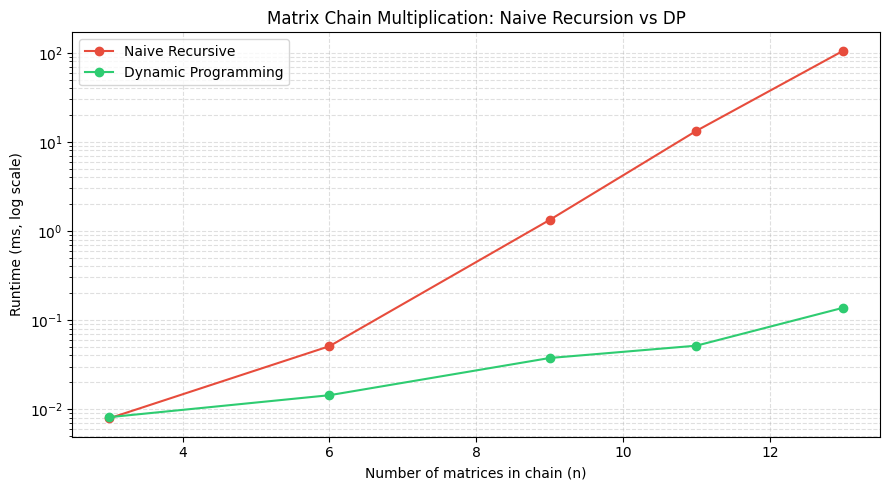

In [9]:
# --- Line chart (log scale on y-axis) ---
plt.figure(figsize=(9, 5))
plt.plot(chain_lengths, recursive_times, marker='o', label='Naive Recursive', color='#e74c3c')
plt.plot(chain_lengths, dp_times, marker='o', label='Dynamic Programming', color='#2ecc71')
plt.yscale('log')
plt.xlabel("Number of matrices in chain (n)")
plt.ylabel("Runtime (ms, log scale)")
plt.title("Matrix Chain Multiplication: Naive Recursion vs DP")
plt.legend()
plt.grid(True, which="both", ls="--", alpha=0.4)
plt.tight_layout()
plt.show()


## Summary Table

| Approach                  | Time Complexity      | Space Complexity | Gives Parenthesization? |
|-----------------------------|-------------------------|---------------------|------------------------------|
| Naive Recursive              | O(4^n / n^1.5) (exponential) | O(n) (call stack)   | Yes (with extra bookkeeping) |
| Dynamic Programming (DP)     | O(n^3)                    | O(n^2)               | Yes (via `split` table)      |

Where `n` = number of matrices in the chain.

**Notes:**
- Matrix Chain Multiplication has **optimal substructure**: the optimal way to
  multiply `Ai..Aj` is built from the optimal ways to multiply its two
  sub-chains, whatever the best split point turns out to be.
- It has **overlapping subproblems**: the same sub-chain `(i, j)` shows up
  while solving many different larger chains — naive recursion recomputes it
  every time, while DP computes it once and reuses it.
- This problem only decides the **order of multiplication** — it does not
  actually perform the multiplications, and it never changes the final numeric
  result (multiplication is associative). It purely minimizes computational
  cost.
- The DP approach here is the same general technique used for other "interval"
  DP problems, such as optimal binary search tree construction and palindrome
  partitioning.
